# Aula 05 — Laboratório Pandas II — Agrupamentos e Joins (Prática) · Conteúdo

**Unidade 1 — Introdução à Ciência de Dados e Python** · ver também: [exercícios](exercicios.ipynb) · [atividades](atividades.ipynb)

**📊 Aula 05 — Laboratório Pandas II — Agrupamentos e Joins (Prática)**

Quinta aula da Unidade 1. Agrupamento de dados (`groupby`, `agg`, named aggregation); reformatação com `pivot_table`; combinação de tabelas (`merge`, `join`); `apply`, `lambda` e introdução ao *method chaining*. Recursos: Jupyter Notebook, mesmo conjunto de dados da Aula 04 (matrículas do IFRN — dados sintéticos). Avaliação: exercício prático entregue no Moodle + formulário avaliativo com 10 questões. Materiais desta aula: livro Tópicos de Estudo (6 capítulos) · apostila completa em PDF (26 páginas) · pacote com o notebook e os dados · exemplo prático comentado · tarefa de entrega · formulário avaliativo.

---
## Tópicos de Estudo — Aula 05: Laboratório Pandas II

### 1. Capítulo 1 — groupby: dividir, aplicar, combinar

Na Aula 04 respondemos "qual a nota média por campus?" com um único `groupby`. Esta aula aprofunda essa ferramenta e acrescenta as que faltavam para transformar uma tabela bruta em respostas: `agg`, `pivot_table`, `merge`, `apply` e o estilo de *method chaining*.

#### O padrão split-apply-combine

Todo `groupby` segue três passos, sempre na mesma ordem:

1.  **Dividir (split)** — o DataFrame é particionado em grupos, um por valor distinto da coluna (ou colunas) de agrupamento.
2.  **Aplicar (apply)** — uma função (média, contagem, soma, uma função personalizada) roda separadamente em cada grupo.
3.  **Combinar (combine)** — os resultados de cada grupo são reunidos de volta em uma única Series ou DataFrame.

Nada disso é mágico: `df.groupby("campus")["nota_final"].mean()` é conceitualmente equivalente a fazer um laço sobre cada campus, calcular a média do subconjunto e depois montar uma tabela com os resultados — só que o Pandas faz isso de forma vetorizada e muito mais rápida.

#### Agrupando por uma coluna

In [ ]:
media_por_campus = df.groupby("campus")["nota_final"].mean().round(2)
media_por_campus.sort_values(ascending=False)

`df.groupby("campus")` sozinho não calcula nada: devolve um objeto `DataFrameGroupBy`, uma promessa de agrupamento. O cálculo só acontece quando se aplica uma função — `.mean()`, `.sum()`, `.count()` etc.

#### Agrupando por várias colunas

In [ ]:
df.groupby(["campus", "turno"])["nota_final"].mean()

O resultado tem um **`MultiIndex`**: um índice hierárquico, com um nível para cada coluna de agrupamento. Para "achatar" esse índice em uma tabela larga, com o segundo nível virando colunas, usa-se `.unstack()` — o assunto do Capítulo 3.

#### `size()` não é `count()`

Esta é a armadilha mais comum do capítulo:

- `df.groupby("campus").size()` — conta **linhas** do grupo, ausentes incluídos.
- `df.groupby("campus")["nota_final"].count()` — conta apenas os valores **não ausentes** daquela coluna específica.

In [ ]:
tamanho   = df.groupby("campus").size()
contagem  = df.groupby("campus")["nota_final"].count()
ausentes  = tamanho - contagem   # quantos "sumiram" na coluna

No conjunto desta disciplina, Natal-Central tem 98 linhas mas apenas 87 notas presentes — a diferença (11) são os estudantes sem `nota_final`, e só aparece quando as duas contagens são comparadas lado a lado.

#### Iterando grupos (bastidores, raramente necessário)

In [ ]:
for campus, grupo in df.groupby("campus"):
    print(campus, len(grupo), grupo["nota_final"].mean())

Serve para entender o mecanismo por dentro; no dia a dia, quase sempre há uma forma vetorizada (agg, pivot_table, apply) que resolve sem laço explícito.

### 2. Capítulo 2 — agg: várias estatísticas de uma vez

`.mean()` sozinho devolve um único número por grupo. Quando é preciso mais de uma estatística ao mesmo tempo, entra o `agg` (abreviação de *aggregate*).

#### Uma lista de funções

In [ ]:
df.groupby("campus")["nota_final"].agg(["mean", "median", "std", "count"])

Cada string da lista é o nome de uma função conhecida do Pandas (`"mean"`, `"sum"`, `"min"`, `"max"`, `"std"`, `"count"`, `"nunique"` …). O resultado é uma tabela com uma coluna por estatística.

#### Várias colunas, cada uma com suas próprias funções

In [ ]:
df.groupby("turno").agg({
    "nota_final": ["mean", "count"],
    "frequencia": "mean",
    "idade": "median",
})

Aqui o resultado tem colunas em **MultiIndex**: `("nota_final", "mean")`, `("nota_final", "count")` etc. Funciona, mas essas colunas de dois níveis são incômodas de referenciar depois (`resultado[("nota_final", "mean")]`).

#### Named aggregation — a forma recomendada

Desde o Pandas 0.25, é possível nomear cada coluna resultante diretamente:

In [ ]:
df.groupby("turno").agg(
    nota_media=("nota_final", "mean"),
    nota_desvio=("nota_final", "std"),
    n_estudantes=("matricula", "count"),
    taxa_aprovacao=("situacao", lambda s: (s == "Aprovado").mean() * 100),
).round(2)

Cada argumento nomeado tem a forma `nome_da_coluna_de_saida=(coluna_de_origem, função)`. O resultado sai com colunas **planas** — `nota_media`, `n_estudantes` — prontas para usar em `sort_values`, gráficos ou um novo `merge`. Sempre que uma tabela de resumo precisar de nomes de coluna claros, esta é a forma preferida.

#### Uma `lambda` dentro do `agg`

`taxa_aprovacao=("situacao", lambda s: (s == "Aprovado").mean() * 100)` merece atenção: dentro do `agg`, `s` é a *coluna daquele grupo* — uma Series só com os valores de `situacao` daquele campus, por exemplo. `s == "Aprovado"` produz uma máscara booleana; `.mean()` dessa máscara é a proporção de `True`; multiplicar por 100 converte para percentual. É a mesma lógica de "máscara booleana + `.mean()`" da Aula 04, agora aplicada dentro de cada grupo.

### 3. Capítulo 3 — pivot_table: o groupby de duas dimensões

Quando o resultado que se quer é uma tabela "larga" — uma categoria nas linhas, outra nas colunas, um valor resumido em cada célula — `pivot_table` é o caminho mais direto.

#### A forma básica

In [ ]:
df.pivot_table(values="nota_final", index="campus",
              columns="turno", aggfunc="mean")

Os quatro parâmetros centrais:

- `values` — a coluna que será resumida dentro de cada célula.
- `index` — a(s) coluna(s) que viram as **linhas** da tabela.
- `columns` — a(s) coluna(s) que viram as **colunas** da tabela.
- `aggfunc` — a função de resumo (`"mean"` por padrão, mas pode ser `"sum"`, `"count"`, uma lista, ou uma função personalizada).

#### É exatamente um groupby + unstack

In [ ]:
df.groupby(["campus", "turno"])["nota_final"].mean().unstack("turno")

Este código produz o **mesmo resultado** do `pivot_table` acima. `pivot_table` é um atalho para esse padrão frequente: agrupar por duas colunas e "desempilhar" uma delas em colunas. Saber os dois caminhos ajuda a reconhecer a mesma operação escrita de formas diferentes.

#### `fill_value` e `margins`

In [ ]:
df.pivot_table(values="matricula", index="campus", columns="situacao",
              aggfunc="count", fill_value=0,
              margins=True, margins_name="Total")

`fill_value=0` substitui por zero as combinações campus×situação que não ocorreram (em vez de `NaN`) — faz sentido aqui porque "zero estudantes nessa situação" é um valor válido, não um dado ausente. `margins=True` acrescenta uma linha e uma coluna de **totais**, o que serve como conferência: a soma das partes deve bater com o total geral.

#### Múltiplas funções de agregação

In [ ]:
df.pivot_table(values="nota_final", index="turno", columns="modalidade",
              aggfunc=["mean", "count"])

Passar uma lista em `aggfunc` produz colunas em dois níveis (a função e depois a categoria) — útil para ver média e tamanho da amostra lado a lado, e lembrar que uma média sobre poucos casos merece menos confiança.

#### `crosstab`: quando só interessa contar

`pd.crosstab(df["turno"], df["situacao"])` é uma versão simplificada, dedicada a tabelas de **contagem** cruzando duas colunas categóricas — equivalente a um `pivot_table` com `aggfunc="count"`, mas com uma assinatura mais direta quando não se precisa de nenhum outro parâmetro.

### 4. Capítulo 4 — merge e join: combinando tabelas

Até aqui, cada tabela foi analisada isoladamente. Mas `matriculas_ifrn_2026.csv` só tem o *nome* do campus e do curso — os detalhes (região, número de docentes, eixo tecnológico, carga horária) estão em `campi_ifrn.xlsx`. `merge` é a operação que junta essas tabelas pela coluna em comum.

#### Merge muitos-para-um

In [ ]:
df_campi = df.merge(campi, on="campus", how="left", validate="m:1")
df_completo = df_campi.merge(cursos, on="curso", how="left", validate="m:1")

Cada estudante (muitos) pertence a exatamente um campus (um) — por isso a relação é "muitos-para-um" (`m:1`). `on="campus"` diz qual coluna serve de **chave** de junção; ela precisa existir, com o mesmo nome e os mesmos valores, nas duas tabelas (é por isso que o `str.strip()` da Aula 04 é indispensável *antes* do merge — `" Mossoró "` não casaria com `"Mossoró"`).

#### `validate`: verificação, não correção

`validate="m:1"` não conserta nada — ele **verifica** que a tabela à direita (`campi`) tem no máximo uma linha por valor de chave. Se por engano `campi` tivesse duas linhas para "Mossoró", um merge sem `validate` duplicaria silenciosamente todas as linhas de estudantes daquele campus; com `validate="m:1"`, o Pandas levanta `MergeError` imediatamente. É uma rede de segurança barata que vale usar sempre que a cardinalidade da relação for conhecida.

#### `how`: o que fazer com quem não casa

|  |  |
|----|----|
| how | Mantém |
| `"inner"` | só as linhas cuja chave existe nas DUAS tabelas |
| `"left"` | TODAS as linhas da tabela da esquerda; sem casamento, entra `NaN` |
| `"right"` | todas as linhas da tabela da direita (o espelho de `"left"`) |
| `"outer"` | todas as linhas de ambas, com `NaN` onde faltar |

In [ ]:
cursos_parcial = cursos[cursos["eixo_tecnologico"] != "Informação e Comunicação"]

inner = df.merge(cursos_parcial, on="curso", how="inner")   # perde quem faz TI
left  = df.merge(cursos_parcial, on="curso", how="left")    # mantém todos, com NaN

`how="left"` é o padrão mais seguro quando o objetivo é *enriquecer* uma tabela principal sem perder nenhuma de suas linhas — é o que se quer ao juntar matrículas com campi ou cursos.

#### Auditando o resultado com `indicator=True`

**Saída mostrada no material:**

```text
checagem = df.merge(cursos, on="curso", how="left", indicator=True)
checagem["_merge"].value_counts()
```

A coluna `_merge` (valores `"both"`, `"left_only"`, `"right_only"`) é a forma mais direta de confirmar que um merge se comportou como esperado — especialmente útil quando as chaves vêm de fontes diferentes e podem ter pequenas divergências de grafia.

#### `join()`: atalho quando a chave é o índice

In [ ]:
campi_idx = campi.set_index("campus")
df.join(campi_idx[["regiao", "num_docentes"]], on="campus")

`join` é essencialmente um `merge` especializado para o caso em que a tabela da direita já está indexada pela chave de junção. O parâmetro `on` diz qual coluna de `df` deve ser comparada com o índice de `campi_idx`.

### 5. Capítulo 5 — apply, lambda e por que vetorizar continua vencendo

#### `apply` em uma única coluna

In [ ]:
df["situacao_curta"] = df["situacao"].apply(
    lambda s: "OK" if s == "Aprovado" else "Não-OK")

`Series.apply(funcao)` chama `funcao` uma vez para **cada valor** da coluna e monta uma nova Series com os retornos. É flexível — a função pode ter qualquer lógica — mas paga o preço de rodar em Python puro, elemento a elemento.

#### `apply(axis=1)`: uma linha inteira por vez

In [ ]:
def classificar(linha):
    if pd.isna(linha["nota_final"]):
        return "Sem nota"
    if linha["nota_final"] >= 85 and linha["frequencia"] >= 90:
        return "Destaque"
    if linha["nota_final"] >= 60:
        return "Regular"
    return "Atenção"

df["perfil"] = df.apply(classificar, axis=1)

Com `axis=1`, cada chamada de `classificar` recebe uma **linha inteira** (uma Series com todas as colunas), o que permite combinar várias colunas numa mesma regra. É a ferramenta certa quando a lógica é condicional demais para caber em uma única expressão vetorizada — mas é também a forma **mais lenta** de operar em um DataFrame, porque o Pandas monta uma Series por linha antes de cada chamada.

#### A mesma regra, vetorizada

In [ ]:
condicoes = [
    df["nota_final"].isna(),
    (df["nota_final"] >= 85) & (df["frequencia"] >= 90),
    df["nota_final"] >= 60,
]
valores = ["Sem nota", "Destaque", "Regular"]
df["perfil_v2"] = np.select(condicoes, valores, default="Atenção")

`np.select` testa uma lista de condições, na ordem, e devolve o valor correspondente à primeira verdadeira — exatamente a lógica do `if/elif/else` de `classificar`, mas avaliada sobre a coluna inteira de uma vez. Em uma base de alguns milhares de linhas a diferença é imperceptível; em milhões de linhas, pode ser a diferença entre segundos e minutos.

#### Quando usar cada um

- Existe uma expressão vetorizada direta (comparação, `np.where`, `np.select`, operação aritmética)? **Use-a.**
- A lógica depende de várias colunas de forma difícil de expressar sem `if`, ou chama uma função externa complexa (uma API, um modelo)? `apply` é aceitável — comece por ele, otimize depois se o desempenho importar.
- Um laço `for` explícito percorrendo `df.iterrows()` quase nunca é a resposta certa: é ainda mais lento que `apply` e existe quase sempre um caminho vetorizado ou um `apply` mais direto.

#### `lambda` não é exclusivo do `apply`

As mesmas funções anônimas aparecem dentro de `agg` (Capítulo 2), de `assign` e de `sort_values(key=...)`. O padrão é sempre o mesmo: `lambda argumento: expressão`, uma forma compacta de escrever uma função de uma linha sem precisar de `def` em outro lugar do código.

### 6. Capítulo 6 — method chaining e pipe

#### O problema das variáveis intermediárias

Uma análise de vários passos, escrita "passo a passo", costuma acumular nomes de variáveis que só servem de ponte:

In [ ]:
tmp1 = df_completo[df_completo["situacao"] != "Trancado"]
tmp2 = tmp1.copy()
tmp2["aprovado"] = tmp2["situacao"] == "Aprovado"
tmp3 = tmp2.groupby(["regiao", "eixo_tecnologico"])
tmp4 = tmp3.agg(n=("matricula", "count"), taxa_aprovacao=("aprovado", "mean"))
tmp5 = tmp4[tmp4["n"] >= 10]
resultado = tmp5.sort_values("taxa_aprovacao", ascending=False)

Funciona, mas cada `tmpN` é uma oportunidade de erro: usar `tmp2` onde deveria ser `tmp3`, esquecer de atualizar uma referência depois de editar o código no meio.

#### A mesma sequência, encadeada

In [ ]:
resultado = (
    df_completo
    .query("situacao != 'Trancado'")
    .assign(aprovado=lambda d: d["situacao"] == "Aprovado")
    .groupby(["regiao", "eixo_tecnologico"])
    .agg(n=("matricula", "count"), taxa_aprovacao=("aprovado", "mean"))
    .query("n >= 10")
    .sort_values("taxa_aprovacao", ascending=False)
)

Os parênteses externos permitem quebrar a expressão em várias linhas sem usar `\`. Cada método devolve um novo objeto, sobre o qual o próximo método é chamado — uma leitura de cima para baixo que corresponde exatamente à ordem das transformações: filtrar, criar coluna, agrupar, agregar, filtrar de novo, ordenar.

#### Duas peças que tornam o encadeamento possível

- `query("expressão")` — filtra linhas usando uma condição escrita como texto, sem precisar repetir o nome do DataFrame nem usar `&`/`|` com parênteses (compare com `df[(df["nota"] > 5) & (df["turno"] == "Noturno")]` contra `df.query("nota > 5 and turno == 'Noturno'")`).
- `assign(coluna=lambda d: expressão)` — cria (ou substitui) uma coluna **sem** precisar de uma atribuição `df["coluna"] = ...` separada. O `lambda d: ...` recebe o DataFrame *naquele ponto da cadeia* — não o `df_completo` original — o que é essencial quando uma etapa anterior já filtrou ou transformou os dados.

#### `.pipe()`: encaixando sua própria função na cadeia

In [ ]:
def com_faixa_carga(d):
    d = d.copy()
    d["carga_faixa"] = pd.cut(d["carga_horaria"],
                              bins=[0, 1200, 1800, 3000],
                              labels=["Até 1200h", "1201–1800h", "Acima de 1800h"])
    return d

resultado2 = (
    df_completo
    .pipe(com_faixa_carga)
    .groupby("carga_faixa", observed=True)["nota_final"]
    .mean()
)

Quando uma etapa é complexa demais para uma `lambda` de uma linha, `.pipe(funcao)` deixa continuar a cadeia chamando uma função nomeada — a função recebe o DataFrame corrente e devolve o próximo, exatamente como qualquer outro método da cadeia. É a forma recomendada de misturar lógica personalizada com method chaining, em vez de "sair" da cadeia com uma variável intermediária.

#### Quando NÃO encadear

Method chaining melhora a leitura quando os passos são poucos e formam uma narrativa clara. Uma cadeia de dez ou mais métodos, ou que precisa ser depurada com frequência (inspecionar o resultado no meio do caminho), costuma ficar mais clara quebrada em duas ou três variáveis com nomes que dizem o que cada etapa representa. A regra não é "sempre encadear" — é "encadear quando isso deixa a intenção mais legível, não menos".

---
## Conteúdo — Aula 05: Laboratório Pandas II (apostila em PDF)

> Convertido de [`Aula05_Pandas_II.pdf`](Aula05_Pandas_II.pdf) (o original está nesta pasta — confira nele figuras e diagramação).

INSTITUTO FEDERAL DE EDUCAÇÃO, CIÊNCIA E TECNOLOGIA DO RIO GRANDE DO NORTE ESPECIALIZAÇÃO EM CIÊNCIA DE DADOS  ·  DISCIPLINA: ANÁLISE E CIÊNCIA DE DADOS

### Aula 05 - Laboratório Pandas II - Agrupamentos e Joins (Prática)

groupby, agg, pivot\_table, combinação de tabelas com merge/join, apply/lambda e method chaining

Unidade

Natureza Unidade 1 - Introdução à Ciência de Dados e Python (Aulas 01-05)

Aula prática (laboratório)

Carga horária

4 h/a - 1 h de exposição guiada + 3 h de laboratório

Pré-

requisitos

Recursos Aula 04 - Laboratório NumPy e Pandas I; DataFrames, seleção, filtragem e leitura de CSV/Excel Jupyter Notebook/Lab, pandas , numpy , mesmo conjunto de dados da Aula 04

Avaliação Exercício prático entregue no Moodle + formulário avaliativo (10 questões)

Professor Plácido Antônio de Souza Neto

### Objetivos de aprendizagem

Ao final desta aula, espera-se que o estudante seja capaz de:

1. Explicar o padrão split-apply-combine subjacente ao groupby e prever o resultado de agrupar por uma ou por várias colunas.
2. Diferenciar size() de count() dentro de um groupby , usando essa diferença para detectar valores ausentes por grupo.
3. Produzir tabelas de resumo com agg() , incluindo a forma de named aggregation , evitando colunas em MultiIndex quando não são necessárias.
4. Construir tabelas com pivot\_table ( index , columns , aggfunc , fill\_value , margins ) e reconhecer sua equivalência com groupby().unstack() .
5. Combinar tabelas com merge , escolhendo corretamente on , how ( inner / left / right / outer ) e validate , e auditar o resultado com indicator=True .
6. Usar join() como atalho de merge quando a chave de junção já é o índice de uma das tabelas.
7. Aplicar apply e lambda em Series e em linhas ( axis=1 ), reconhecendo quando uma alternativa vetorizada ( np.where , np.select ) é preferível por desempenho.
8. Escrever pipelines de análise em estilo method chaining , com query , assign e pipe , evitando variáveis intermediárias desnecessárias.

### Sumário

### Parte I - Fundamentos teóricos

- 1.1 groupby: dividir, aplicar, combinar
- 1.2 agg: várias estatísticas de uma vez
- 1.3 pivot\_table: o groupby de duas dimensões
- 1.4 merge e join: combinando tabelas
- 1.5 apply, lambda e por que vetorizar continua vencendo
- 1.6 method chaining e pipe

### Parte II - Tópicos de estudo dirigido (roteiro de leitura)

- Parte III - Laboratório guiado: matrículas, campi e cursos do IFRN

Parte IV - Exercício prático avaliativo (entrega no Moodle)

Parte V - Formulário avaliativo (10 questões)

Apêndice A - Colinha de comandos

Apêndice B - Referências e leituras recomendadas

### SOBRE OS DADOS USADOS NESTA AULA

Esta aula usa o mesmo conjunto de dados sintético da Aula 04 - matriculas\_ifrn\_2026.csv e campi\_ifrn.xlsx - como continuação direta daquele laboratório. Os nomes de campi e cursos são reais; matrículas, nomes de estudantes, notas, frequências e situações continuam sendo sintéticos, gerados com semente fixa. A escolha é deliberada: reaproveitar os mesmos dados evita o custo de aprender um domínio novo e permite que o foco desta aula recaia inteiramente sobre as técnicas novas - groupby , agg , pivot\_table , merge / join , apply e method chaining - aplicadas a uma tabela que você já conhece. Nenhuma conclusão sobre o IFRN real pode ser extraída desses números.

### Parte I - Fundamentos teóricos

groupby, agg, pivot\_table, merge/join, apply/lambda e method chaining - em continuidade direta com a Aula 04

A Aula 04 fechou com uma pergunta respondida por um único groupby : "em quais campi a nota média supera a média geral?". Esta aula retoma exatamente esse ponto e acrescenta as ferramentas que faltavam para transformar uma tabela bruta em respostas completas: agregações com múltiplas estatísticas ( agg ), reformatação em tabelas largas ( pivot\_table ), combinação de tabelas ( merge / join ), transformações personalizadas ( apply / lambda ) e um estilo de escrita que encadeia tudo isso com clareza ( method chaining ).

### 1.1 groupby: dividir, aplicar, combinar

Na Aula 04 respondemos "qual a nota média por campus?" com um único groupby . Esta aula aprofunda essa ferramenta e acrescenta as que faltavam para transformar uma tabela bruta em respostas: agg , pivot\_table , merge , apply e o estilo de method chaining .

### O padrão split-apply-combine

Todo groupby segue três passos, sempre na mesma ordem:

1. Dividir (split) - o DataFrame é particionado em grupos, um por valor distinto da coluna (ou colunas) de agrupamento.
2. Aplicar (apply) - uma função (média, contagem, soma, uma função personalizada) roda separadamente em cada grupo.
3. Combinar (combine) - os resultados de cada grupo são reunidos de volta em uma única Series ou DataFrame.

Nada disso é mágico: df.groupby("campus")["nota\_final"].mean() é conceitualmente equivalente a fazer um laço sobre cada campus, calcular a média do subconjunto e depois montar uma tabela com os resultados - só que o Pandas faz isso de forma vetorizada e muito mais rápida.

### Agrupando por uma coluna

In [ ]:
media_por_campus = df.groupby("campus")["nota_final"].mean().round(2)
media_por_campus.sort_values(ascending=False)

df.groupby("campus") sozinho não calcula nada: devolve um objeto DataFrameGroupBy , uma promessa de agrupamento. O cálculo só acontece quando se aplica uma função - .mean() , .sum() , .count() etc.

### Agrupando por várias colunas

In [ ]:
df.groupby(["campus", "turno"])["nota_final"].mean()

O resultado tem um MultiIndex : um índice hierárquico, com um nível para cada coluna de agrupamento. Para "achatar" esse índice em uma tabela larga, com o segundo nível virando colunas, usa-se .unstack() - o assunto do Capítulo 3.

### size() não é count()

Esta é a armadilha mais comum do capítulo:

- df.groupby("campus").size() - conta linhas do grupo, ausentes incluídos.
- df.groupby("campus")["nota\_final"].count() - conta apenas os valores não ausentes daquela coluna específica.

In [ ]:
tamanho   = df.groupby("campus").size()
contagem  = df.groupby("campus")["nota_final"].count()
ausentes  = tamanho - contagem   # quantos "sumiram" na coluna

No conjunto desta disciplina, Natal-Central tem 98 linhas mas apenas 87 notas presentes - a diferença (11) são os estudantes sem nota\_final , e só aparece quando as duas contagens são comparadas lado a lado.

### Iterando grupos (bastidores, raramente necessário)

In [ ]:
for campus, grupo in df.groupby("campus"):
    print(campus, len(grupo), grupo["nota_final"].mean())

Serve para entender o mecanismo por dentro; no dia a dia, quase sempre há uma forma vetorizada (agg, pivot\_table, apply) que resolve sem laço explícito.

### SIZE() NÃO É COUNT()

groupby(...).size() conta linhas do grupo, ausentes incluídos. groupby(...)["coluna"].count() conta apenas os valores não ausentes daquela coluna. A diferença entre as duas é, exatamente, o número de ausentes por grupo - uma forma rápida de auditar dados sem chamar isna() separadamente.

### 1.2 agg: várias estatísticas de uma vez

.mean() sozinho devolve um único número por grupo. Quando é preciso mais de uma estatística ao mesmo tempo, entra o agg (abreviação de aggregate ).

### Uma lista de funções

In [ ]:
df.groupby("campus")["nota_final"].agg(["mean", "median", "std", "count"])

Cada string da lista é o nome de uma função conhecida do Pandas ( "mean" , "sum" , "min" , "max" , "std" , "count" , "nunique" …). O resultado é uma tabela com uma coluna por estatística.

### Várias colunas, cada uma com suas próprias funções

In [ ]:
df.groupby("turno").agg({
    "nota_final": ["mean", "count"],
    "frequencia": "mean",
    "idade": "median",
})

Aqui o resultado tem colunas em MultiIndex : ("nota\_final", "mean") , ("nota\_final", "count") etc. Funciona, mas essas colunas de dois níveis são incômodas de referenciar depois ( resultado[("nota\_final", "mean")] ).

### Named aggregation - a forma recomendada

Desde o Pandas 0.25, é possível nomear cada coluna resultante diretamente:

In [ ]:
df.groupby("turno").agg(
    nota_media=("nota_final", "mean"),
    nota_desvio=("nota_final", "std"),
    n_estudantes=("matricula", "count"),
    taxa_aprovacao=("situacao", lambda s: (s == "Aprovado").mean() * 100),
).round(2)

Cada argumento nomeado tem a forma nome\_da\_coluna\_de\_saida=(coluna\_de\_origem, função) . O resultado sai com colunas planas - nota\_media , n\_estudantes - prontas para usar em sort\_values , gráficos ou um novo merge . Sempre que uma tabela de resumo precisar de nomes de coluna claros, esta é a forma preferida.

### Uma lambda dentro do agg

taxa\_aprovacao=("situacao", lambda s: (s == "Aprovado").mean() * 100) merece atenção: dentro do agg , s é a coluna daquele grupo - uma Series só com os valores de situacao daquele campus, por exemplo. s == "Aprovado" produz uma máscara booleana; .mean() dessa máscara é a proporção de True ; multiplicar por 100 converte para percentual. É a mesma lógica de "máscara booleana + .mean() " da Aula 04, agora aplicada dentro de cada grupo.

### 1.3 pivot\_table: o groupby de duas dimensões

Quando o resultado que se quer é uma tabela "larga" - uma categoria nas linhas, outra nas colunas, um valor resumido em cada célula - pivot\_table é o caminho mais direto.

### A forma básica

In [ ]:
df.pivot_table(values="nota_final", index="campus",
              columns="turno", aggfunc="mean")

Os quatro parâmetros centrais:

- values - a coluna que será resumida dentro de cada célula.
- index - a(s) coluna(s) que viram as linhas da tabela.
- columns - a(s) coluna(s) que viram as colunas da tabela.

- aggfunc - a função de resumo ( "mean" por padrão, mas pode ser "sum" , "count" , uma lista, ou uma função personalizada).

### É exatamente um groupby + unstack

In [ ]:
df.groupby(["campus", "turno"])["nota_final"].mean().unstack("turno")

Este código produz o mesmo resultado do pivot\_table acima. pivot\_table é um atalho para esse padrão frequente: agrupar por duas colunas e "desempilhar" uma delas em colunas. Saber os dois caminhos ajuda a reconhecer a mesma operação escrita de formas diferentes.

### fill\_value e margins

In [ ]:
df.pivot_table(values="matricula", index="campus", columns="situacao",
              aggfunc="count", fill_value=0,
              margins=True, margins_name="Total")

fill\_value=0 substitui por zero as combinações campus×situação que não ocorreram (em vez de NaN ) - faz sentido aqui porque "zero estudantes nessa situação" é um valor válido, não um dado ausente. margins=True acrescenta uma linha e uma coluna de totais , o que serve como conferência: a soma das partes deve bater com o total geral.

### Múltiplas funções de agregação

In [ ]:
df.pivot_table(values="nota_final", index="turno", columns="modalidade",
              aggfunc=["mean", "count"])

Passar uma lista em aggfunc produz colunas em dois níveis (a função e depois a categoria) - útil para ver média e tamanho da amostra lado a lado, e lembrar que uma média sobre poucos casos merece menos confiança.

### crosstab : quando só interessa contar

pd.crosstab(df["turno"], df["situacao"]) é uma versão simplificada, dedicada a tabelas de contagem cruzando duas colunas categóricas - equivalente a um pivot\_table com aggfunc="count" , mas com uma assinatura mais direta quando não se precisa de nenhum outro parâmetro.

### 1.4 merge e join: combinando tabelas

Até aqui, cada tabela foi analisada isoladamente. Mas matriculas\_ifrn\_2026.csv só tem o nome do campus e do curso - os detalhes (região, número de docentes, eixo tecnológico, carga horária) estão em campi\_ifrn.xlsx . merge é a operação que junta essas tabelas pela coluna em comum.

### Merge muitos-para-um

In [ ]:
df_campi = df.merge(campi, on="campus", how="left", validate="m:1")
df_completo = df_campi.merge(cursos, on="curso", how="left", validate="m:1")

Cada estudante (muitos) pertence a exatamente um campus (um) - por isso a relação é "muitos-para-um" ( m:1 ). on="campus" diz qual coluna serve de chave de junção; ela precisa existir, com o mesmo nome e os mesmos valores, nas duas tabelas (é por isso que o str.strip() da Aula 04 é indispensável antes do merge - " Mossoró " não casaria com "Mossoró" ).

### validate : verificação, não correção

validate="m:1" não conserta nada - ele verifica que a tabela à direita ( campi ) tem no máximo uma linha por valor de chave. Se por engano campi tivesse duas linhas para "Mossoró", um merge sem validate duplicaria silenciosamente todas as linhas de estudantes daquele campus; com validate="m:1" , o Pandas levanta MergeError imediatamente. É uma rede de segurança barata que vale usar sempre que a cardinalidade da relação for conhecida.

how : o que fazer com quem não casa

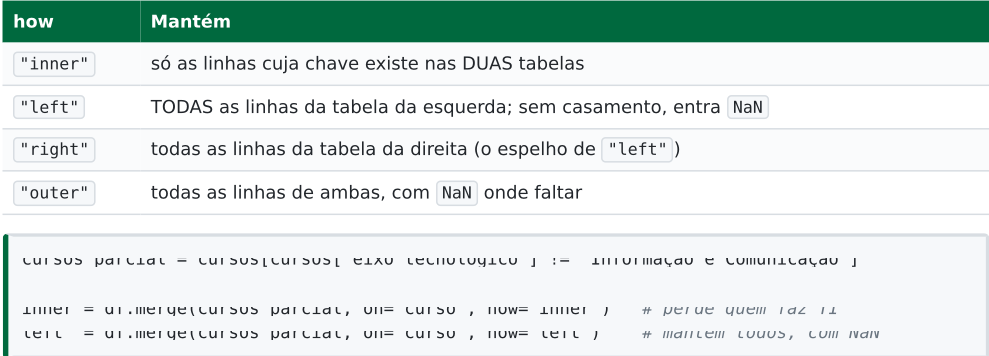

how="left" é o padrão mais seguro quando o objetivo é enriquecer uma tabela principal sem perder nenhuma de suas linhas - é o que se quer ao juntar matrículas com campi ou cursos.

### Auditando o resultado com indicator=True

In [ ]:
checagem = df.merge(cursos, on="curso", how="left", indicator=True)
checagem["_merge"].value_counts()

A coluna \_merge (valores "both" , "left\_only" , "right\_only" ) é a forma mais direta de confirmar que um merge se comportou como esperado - especialmente útil quando as chaves vêm de fontes diferentes e podem ter pequenas divergências de grafia.

### join() : atalho quando a chave é o índice

In [ ]:
campi_idx = campi.set_index("campus")
df.join(campi_idx[["regiao", "num_docentes"]], on="campus")

join é essencialmente um merge especializado para o caso em que a tabela da direita já está indexada pela chave de junção. O parâmetro on diz qual coluna de df deve ser comparada com o índice de campi\_idx .

### VALIDATE VERIFICA, NÃO CORRIGE

validate="m:1" não conserta nada nos dados: ele apenas confirma que a cardinalidade declarada é verdadeira e interrompe o merge com MergeError quando não é. Sem validate , uma tabela à direita com chaves duplicadas duplicaria silenciosamente linhas da tabela à esquerda - um dos erros mais difíceis de perceber depois de feito. Declarar a cardinalidade esperada é uma rede de segurança barata e deve ser hábito, não exceção.

### 1.5 apply, lambda e por que vetorizar continua vencendo

### apply em uma única coluna

In [ ]:
df["situacao_curta"] = df["situacao"].apply(
    lambda s: "OK" if s == "Aprovado" else "Não-OK")

Series.apply(funcao) chama funcao uma vez para cada valor da coluna e monta uma nova Series com os retornos. É flexível - a função pode ter qualquer lógica - mas paga o preço de rodar em Python puro, elemento a elemento.

### apply(axis=1) : uma linha inteira por vez

In [ ]:
def classificar(linha):
    if pd.isna(linha["nota_final"]):
        return "Sem nota"
    if linha["nota_final"] >= 85 and linha["frequencia"] >= 90:
        return "Destaque"
    if linha["nota_final"] >= 60:
        return "Regular"
    return "Atenção"

df["perfil"] = df.apply(classificar, axis=1)

Com axis=1 , cada chamada de classificar recebe uma linha inteira (uma Series com todas as colunas), o que permite combinar várias colunas numa mesma regra. É a ferramenta certa quando a lógica é condicional demais para caber em uma única expressão vetorizada - mas é também a forma mais lenta de operar em um DataFrame, porque o Pandas monta uma Series por linha antes de cada chamada.

### A mesma regra, vetorizada

In [ ]:
condicoes = [
    df["nota_final"].isna(),
    (df["nota_final"] >= 85) & (df["frequencia"] >= 90),
    df["nota_final"] >= 60,
]
valores = ["Sem nota", "Destaque", "Regular"]
df["perfil_v2"] = np.select(condicoes, valores, default="Atenção")

np.select testa uma lista de condições, na ordem, e devolve o valor correspondente à primeira verdadeira - exatamente a lógica do if/elif/else de classificar , mas avaliada sobre a coluna inteira de uma vez. Em uma base de alguns milhares de linhas a diferença é imperceptível; em milhões de linhas, pode ser a diferença entre segundos e minutos.

### Quando usar cada um

- Existe uma expressão vetorizada direta (comparação, np.where , np.select , operação aritmética)? Use-a.
- A lógica depende de várias colunas de forma difícil de expressar sem if , ou chama uma função externa complexa (uma API, um modelo)? apply é aceitável - comece por ele, otimize depois se o desempenho importar.
- Um laço for explícito percorrendo df.iterrows() quase nunca é a resposta certa: é ainda mais lento que apply e existe quase sempre um caminho vetorizado ou um apply mais direto.

### lambda não é exclusivo do apply

As mesmas funções anônimas aparecem dentro de agg (Capítulo 2), de assign e de sort\_values(key=...) . O padrão é sempre o mesmo: lambda argumento: expressão , uma forma compacta de escrever uma função de uma linha sem precisar de def em outro lugar do código.

### 1.6 method chaining e pipe

### O problema das variáveis intermediárias

Uma análise de vários passos, escrita "passo a passo", costuma acumular nomes de variáveis que só servem de ponte:

In [ ]:
tmp1 = df_completo[df_completo["situacao"] != "Trancado"]
tmp2 = tmp1.copy()
tmp2["aprovado"] = tmp2["situacao"] == "Aprovado"
tmp3 = tmp2.groupby(["regiao", "eixo_tecnologico"])
tmp4 = tmp3.agg(n=("matricula", "count"), taxa_aprovacao=("aprovado", "mean"))
tmp5 = tmp4[tmp4["n"] >= 10]
resultado = tmp5.sort_values("taxa_aprovacao", ascending=False)

Funciona, mas cada tmpN é uma oportunidade de erro: usar tmp2 onde deveria ser tmp3 , esquecer de atualizar uma referência depois de editar o código no meio.

### A mesma sequência, encadeada

In [ ]:
resultado = (
    df_completo
    .query("situacao != 'Trancado'")
    .assign(aprovado=lambda d: d["situacao"] == "Aprovado")
    .groupby(["regiao", "eixo_tecnologico"])
    .agg(n=("matricula", "count"), taxa_aprovacao=("aprovado", "mean"))
    .query("n >= 10")
    .sort_values("taxa_aprovacao", ascending=False)
)

Os parênteses externos permitem quebrar a expressão em várias linhas sem usar \ . Cada método devolve um novo objeto, sobre o qual o próximo método é chamado - uma leitura de cima para baixo que corresponde exatamente à ordem das transformações: filtrar, criar coluna, agrupar, agregar, filtrar de novo, ordenar.

### Duas peças que tornam o encadeamento possível

- query("expressão") - filtra linhas usando uma condição escrita como texto, sem precisar repetir o nome do DataFrame nem usar &amp; / | com parênteses (compare com df[(df["nota"] &gt; 5) &amp; (df["turno"] == "Noturno")] contra df.query("nota &gt; 5 and turno == 'Noturno'") ).
- assign(coluna=lambda d: expressão) - cria (ou substitui) uma coluna sem precisar de uma atribuição df["coluna"] = ... separada. O lambda d: ... recebe o DataFrame naquele ponto da cadeia - não o df\_completo original - o que é essencial quando uma etapa anterior já filtrou ou transformou os dados.

### .pipe() : encaixando sua própria função na cadeia

In [ ]:
def com_faixa_carga(d):
    d = d.copy()
    d["carga_faixa"] = pd.cut(d["carga_horaria"],
                              bins=[0, 1200, 1800, 3000],
                              labels=["Até 1200h", "1201–1800h", "Acima de 1800h"])
    return d

resultado2 = (
    df_completo
    .pipe(com_faixa_carga)
    .groupby("carga_faixa", observed=True)["nota_final"]
    .mean()
)

Quando uma etapa é complexa demais para uma lambda de uma linha, .pipe(funcao) deixa continuar a cadeia chamando uma função nomeada - a função recebe o DataFrame corrente e devolve o próximo, exatamente como qualquer outro método da cadeia. É a forma recomendada de misturar lógica personalizada com method chaining, em vez de "sair" da cadeia com uma variável intermediária.

### Quando NÃO encadear

Method chaining melhora a leitura quando os passos são poucos e formam uma narrativa clara. Uma cadeia de dez ou mais métodos, ou que precisa ser depurada com frequência (inspecionar o resultado no meio do caminho), costuma ficar mais clara quebrada em duas ou três variáveis com nomes que dizem o que cada etapa representa. A regra não é "sempre encadear" - é "encadear quando isso deixa a intenção mais legível, não menos".

### Parte II - Tópicos de estudo dirigido

Roteiro de leitura individual, correspondente ao livro "T ópicos de Estudo - Aula 05" no Moodle

O livro da Aula 05 no AVA reproduz, capítulo a capítulo, o conteúdo da Parte I acima, com exercícios curtos de fixação ao final de cada um. Não é leitura nova: é a mesma Parte I, em formato de estudo dirigido, para revisar antes do laboratório e do formulário avaliativo. Estude com o Jupyter aberto - leia um trecho, execute, altere um parâmetro, observe o que muda.

| Cap. | Domine | Erro frequente a evitar |
|--------|----------------------------------------------------------------------------------------------------------------------|-------------------------------------------------------------------------------------------------------------|
| 1 | groupby : split-apply- combine; agrupar por uma ou várias colunas; size() × count() . | Confundir contagem de linhas com contagem de valores não ausentes. |
| 2 | agg com lista de funções, com dicionário por coluna e, sobretudo, named aggregation . | Usar a forma que produz colunas em MultiIndex quando o objetivo é uma tabela de saída simples. |
| 3 | pivot_table : values , index , columns , aggfunc , fill_value , margins ; sua equivalência com groupby().unstack() . | Esquecer fill_value=0 quando "ausência de casos" é um valor válido, não um dado faltando. |
| 4 | merge com on , how e validate ; auditoria com indicator=True ; join() pela chave-índice. | Fazer merge sem validate nem conferência do shape antes/depois, arriscando duplicação silenciosa de linhas. |
| 5 | apply em Series e em linhas ( axis=1 ); quando uma alternativa vetorizada ( np.where , np.select ) é preferível. | Escrever apply(axis=1) por reflexo quando existe uma expressão vetorizada direta e mais rápida. |
| 6 | Method chaining com query , assign e pipe ; quando encadear e quando não encadear. | Encadear tantos métodos que a cadeia fica mais difícil de ler do que o código em passos separados. |

### AUTOAVALIAÇÃO RÁPIDA

Você está pronto para o laboratório quando conseguir, de memória, escrever as linhas que (1) calculam nota média e número de estudantes por turno com named aggregation, (2) constroem uma pivot\_table de campus × situação com totais, (3) juntam matrículas com campi e cursos usando validate="m:1" , e (4) reescrevem uma regra condicional escrita com apply(axis=1) na forma vetorizada equivalente.

### Parte III - Laboratório guiado

Matrículas, campi e cursos do IFRN (dados sintéticos, continuação da Aula 04) - todas as saídas abaixo foram produzidas pelo código apresentado

Mesmos arquivos da Aula 04, na pasta dados/ ao lado do notebook - matriculas\_ifrn\_2026.csv e campi\_ifrn.xlsx (abas campi e cursos ) - agora usados também para os merges desta aula.

### Passo 0 - Retomando a Aula 04: leitura e limpeza

In [ ]:
df = pd.read_csv(
    "dados/matriculas_ifrn_2026.csv",
    sep=";", decimal=",", encoding="utf-8",
    dtype={"matricula": "string"},
)
df["campus"] = df["campus"].str.strip()
df = df.drop_duplicates().reset_index(drop=True)

campi = pd.read_excel("dados/campi_ifrn.xlsx", sheet_name="campi")
cursos = pd.read_excel("dados/campi_ifrn.xlsx", sheet_name="cursos")

print(f"matrículas: {df.shape} | campi: {campi.shape} | cursos: {cursos.shape}")

```
matrículas: (480, 12) | campi: (12, 5) | cursos: (10, 4)
```

### Passo 1 - groupby

In [ ]:
# 1a. groupby de uma coluna + uma estatística
media_por_campus = df.groupby("campus")["nota_final"].mean().round(2)
print(media_por_campus.sort_values(ascending=False))

```
campus
Santa Cruz                 74.55
Currais Novos               72.28
Apodi                       71.69
Mossoró                     71.66
Natal-Zona Norte            70.36
Caicó                       70.04
Pau dos Ferros              68.70
Natal-Central                68.07
Macau                       67.18
Parnamirim                  66.97
São Gonçalo do Amarante     66.67
João Câmara                 63.78
Name: nota_final, dtype: float64
```

In [ ]:
# 1b. groupby de VÁRIAS colunas
media_por_campus_turno = (
    df.groupby(["campus", "turno"])["nota_final"].mean().round(2)
)
print(media_por_campus_turno.head(8))
print("Tipo do índice:", type(media_por_campus_turno.index).__name__)

```
campus         turno
Apodi          Matutino      69.89
               Noturno       71.98
               Vespertino    73.74
Caicó          Matutino      67.95
               Noturno       72.37
               Vespertino    67.90
Currais Novos  Matutino      75.28
               Noturno       66.79
Name: nota_final, dtype: float64

Tipo do índice: MultiIndex
```

In [ ]:
# 1c. size() x count() — cuidado com a diferença
tamanho = df.groupby("campus").size()
contagem = df.groupby("campus")["nota_final"].count()
comparacao = pd.DataFrame({"linhas": tamanho, "notas_presentes": contagem})
comparacao["ausentes"] = comparacao["linhas"] - comparacao["notas_presentes"]
print(comparacao.sort_values("ausentes", ascending=False).head(6))

```
                  linhas  notas_presentes  ausentes
campus
Natal-Central         98               87        11
Mossoró               70               62         8
Pau dos Ferros        33               27         6
Apodi                 34               31         3
Natal-Zona Norte      42               39         3
Macau                 34               32         2
```

Natal-Central tem 98 linhas mas apenas 87 notas presentes - a diferença (11) são os estudantes ainda sem nota\_final , e só aparece quando as duas contagens são comparadas lado a lado.



In [ ]:
# 2a. agg() com uma lista de funções
resumo = df.groupby("campus")["nota_final"].agg(["mean", "median", "std", "count"])
print(resumo.round(2).sort_values("mean", ascending=False).head(6))

```
                   mean  median    std  count
campus
Santa Cruz        74.55   75.10  12.51     23
Currais Novos     72.28   73.05  12.37     24
Apodi             71.69   73.30  13.96     31
Mossoró           71.66   73.90  13.73     62
Natal-Zona Norte  70.36   71.10  11.31     39
Caicó             70.04   69.20   8.17     21
```

In [ ]:
# 2b. agg() em várias colunas ao mesmo tempo
resumo2 = df.groupby("turno").agg({
    "nota_final": ["mean", "count"],
    "frequencia": "mean",
    "idade": "median",
})
print(resumo2.round(2))
print("Colunas viraram MultiIndex:", resumo2.columns.tolist())

```
           nota_final       frequencia  idade
                 mean count       mean median
turno
Matutino        70.90   139      86.42   25.0
Noturno         66.76   198      86.32   23.0
Vespertino      71.62   102      84.73   23.5

Colunas viraram MultiIndex: [('nota_final', 'mean'), ('nota_final', 'count'),
('frequencia', 'mean'), ('idade', 'median')]
```

In [ ]:
# 2c. Named aggregation — a forma recomendada (colunas planas)
resumo3 = df.groupby("turno").agg(
    nota_media=("nota_final", "mean"),
    nota_desvio=("nota_final", "std"),
    n_estudantes=("matricula", "count"),
    taxa_aprovacao=("situacao", lambda s: (s == "Aprovado").mean() * 100),
).round(2)
print(resumo3)

| | nota_media | nota_desvio | n_estudantes | taxa_aprovacao |
|------------|--------------|---------------|----------------|------------------|
| turno | | | | |
| Matutino | 70.90 | 12.05 | 150 | 65.33 |
| Noturno | 66.76 | 12.47 | 214 | 55.14 |
| Vespertino | 71.62 | 12.12 | 116 | 56.03 |

### Passo 3 - pivot\_table

In [ ]:
# 3a. pivot_table básica: campus x turno, nota média
tabela = df.pivot_table(
    values="nota_final", index="campus", columns="turno", aggfunc="mean"
).round(1)
print(tabela.head(6))

| turno | Matutino | Noturno | Vespertino |
|---------------|------------|-----------|--------------|
| campus | | | |
| Apodi | 69.9 | 72.0 | 73.7 |
| Caicó | 68.0 | 72.4 | 67.9 |
| Currais Novos | 75.3 | 66.8 | 78.5 |
| João Câmara | 70.2 | 61.8 | 61.0 |
| Macau | 70.7 | 65.3 | 69.8 |
| Mossoró | 74.3 | 66.2 | 73.8 |

In [ ]:
# 3b. pivot_table com contagem e margens (totais)
contagem_pivot = df.pivot_table(
    values="matricula", index="campus", columns="situacao",
    aggfunc="count", fill_value=0, margins=True, margins_name="Total",
)
print(contagem_pivot.tail(4))

| situacao | Aprovado | Em curso | por falta | Reprovado por nota | Trancado |
|-------------------------|------------|------------|-------------|----------------------|------------|
| Total | | | | | |
| campus | | | | | |
| Pau dos Ferros | 18 | 4 | 3 | 6 | 2 |
| 33 | | | | | |
| Santa Cruz | 16 | 0 | 4 | 3 | 2 |
| 25 | | | | | |
| São Gonçalo do Amarante | 13 | 0 | 7 | 8 | 2 |
| 30 | | | | | |
| Total | 281 | 14 | 72 | 86 | 27 |
| 480 | | | | | |

```
values="nota_final", index="turno", columns="modalidade",
```

In [ ]:
# 3c. pivot_table com múltiplas agregações multi = df.pivot_table( aggfunc=["mean", "count"], ).round(1) print(multi)

| modalidade turno | mean EaD | Presencial | count EaD | Presencial |
|--------------------|------------|--------------|-------------|--------------|
| Matutino | 74.9 | 70.0 | 25 | 114 |
| Noturno | 66.3 | 66.9 | 51 | 147 |
| Vespertino | 73.0 | 71.2 | 22 | 80 |

In [ ]:
# 3d. groupby().unstack() faz o mesmo que pivot_table
via_groupby = (df.groupby(["campus", "turno"])["nota_final"]
                 .mean().unstack("turno").round(1))
print("Equivalente ao 3a?", via_groupby.head(2).equals(tabela.head(2)))

Equivalente ao 3a? True

### Passo 4 - merge / join

In [ ]:
# 4a. merge muitos-para-um: matrículas + campi
df_campi = df.merge(campi, on="campus", how="left", validate="m:1")
print(f"Linhas antes: {len(df)} | depois do merge: {len(df_campi)}")

In [ ]:
print(df_campi[["nome", "campus", "regiao", "num_docentes"]].head(3))

```
Linhas antes: 480 | depois do merge: 480
                          nome         campus        regiao  num_docentes
0  Wagner Cavalcante Fernandes          Apodi         Oeste            88
1        Zélia Santos Oliveira          Macau  Costa Branca            71
2          Zélia Barbosa Costa  Currais Novos        Seridó            99
```

In [ ]:
# 4b. merge muitos-para-um: + cursos
df_completo = df_campi.merge(cursos, on="curso", how="left", validate="m:1")
print(df_completo[["nome", "curso", "eixo_tecnologico", "carga_horaria"]].head(3))
print("Colunas ausentes após os merges (deveria ser 0 em ambos):")
print(df_completo[["regiao", "eixo_tecnologico"]].isna().sum())

```
                          nome                                  curso          eixo_tecnologico
carga_horaria
0  Wagner Cavalcante Fernandes  Análise e Desenvolvimento de Sistemas  Informação e Comunicação
2400
1        Zélia Santos Oliveira                  Redes de Computadores  Informação e Comunicação
1200
2          Zélia Barbosa Costa                       Ciência de Dados  Informação e Comunicação
400

Colunas ausentes após os merges (deveria ser 0 em ambos):
regiao              0
eixo_tecnologico    0
dtype: int64

# 4c. how='inner' x how='left': o que se perde
cursos_sem_ti = cursos[cursos["eixo_tecnologico"] != "Informação e Comunicação"]
inner = df.merge(cursos_sem_ti, on="curso", how="inner")
left = df.merge(cursos_sem_ti, on="curso", how="left")
print(f"inner: {len(inner)} linhas (só cursos que casaram)")
print(f"left : {len(left)} linhas (todas as linhas de df, com NaN onde não casou)")
print(f"NaN em 'eixo_tecnologico' no left: {left['eixo_tecnologico'].isna().sum()}")

inner: 271 linhas (só cursos que casaram)
left : 480 linhas (todas as linhas de df, com NaN onde não casou)
NaN em 'eixo_tecnologico' no left: 209

# 4d. indicator=True: de onde veio cada linha
checagem = df.merge(cursos, on="curso", how="left", indicator=True)
print(checagem["_merge"].value_counts())
```

```
_merge
both          480
left_only       0
right_only      0
Name: count, dtype: int64
```

In [ ]:
# 4e. join() — atalho quando a chave é o índice
campi_idx = campi.set_index("campus")
df_join = df.join(campi_idx[["regiao", "num_docentes"]], on="campus")
print(df_join[["nome", "campus", "regiao"]].head(3))

```
                          nome         campus        regiao
0  Wagner Cavalcante Fernandes          Apodi         Oeste
1        Zélia Santos Oliveira          Macau  Costa Branca
2          Zélia Barbosa Costa  Currais Novos        Seridó
```

### Passo 5 - apply , lambda e method chaining

In [ ]:
# 5a. apply em uma Series
df_completo["situacao_curta"] = df_completo["situacao"].apply(
    lambda s: "OK" if s == "Aprovado" else "Não-OK"
)
print(df_completo["situacao_curta"].value_counts())

```
situacao_curta
OK        281
Não-OK    199
Name: count, dtype: int64
```

In [ ]:
# 5b. apply(axis=1) — CUSTOSO, use com critério
def classificar(linha):
    if pd.isna(linha["nota_final"]):
        return "Sem nota"
    if linha["nota_final"] >= 85 and linha["frequencia"] >= 90:
        return "Destaque"
    if linha["nota_final"] >= 60:
        return "Regular"
    return "Atenção"

df_completo["perfil"] = df_completo.apply(classificar, axis=1)
print(df_completo["perfil"].value_counts())

# A MESMA coisa, vetorizada (milhares de vezes mais rápida em bases grandes)
condicoes = [
    df_completo["nota_final"].isna(),
    (df_completo["nota_final"] >= 85) & (df_completo["frequencia"] >= 90),
    df_completo["nota_final"] >= 60,
]
valores = ["Sem nota", "Destaque", "Regular"]
df_completo["perfil_vetorizado"] = np.select(condicoes, valores, default="Atenção")
print((df_completo["perfil"] == df_completo["perfil_vetorizado"]).all())

```
perfil
Regular     318
Atenção     102
Sem nota     41
Destaque     19
Name: count, dtype: int64

True
```

In [ ]:
# 5c. lambda dentro de agg() — resumos sob medida
faixa_etaria = df_completo.groupby("turno").agg(
    pct_menores_20=("idade", lambda s: (s < 20).mean() * 100),
    pct_acima_30=("idade", lambda s: (s > 30).mean() * 100),
).round(1)
print(faixa_etaria)

```
            pct_menores_20  pct_acima_30
turno
Matutino              17.3          16.7
Noturno               27.6           7.0
Vespertino            25.0          13.8
```

In [ ]:
# 5d. method chaining — um pipeline legível, sem variáveis intermediárias
resultado = (
    df_completo
    .query("situacao != 'Trancado'")
    .assign(aprovado=lambda d: d["situacao"] == "Aprovado")
    .groupby(["regiao", "eixo_tecnologico"])
    .agg(
        n_estudantes=("matricula", "count"),
        taxa_aprovacao=("aprovado", "mean"),
        nota_media=("nota_final", "mean"),
    )
    .round(3)
    .query("n_estudantes >= 10")
    .sort_values("taxa_aprovacao", ascending=False)
)
print(resultado.head(8))

```
                                        n_estudantes  taxa_aprovacao  nota_media
regiao        eixo_tecnologico
Metropolitana Produção Industrial                 12           0.917      75.508
Oeste         Recursos Naturais                   14           0.857      78.162
              Gestão e Negócios                   19           0.842      69.232
Metropolitana Recursos Naturais                   21           0.714      69.624
Oeste         Produção Industrial                 16           0.688      70.013
Costa Branca  Informação e Comunicação            14           0.643      68.408
Oeste         Informação e Comunicação            50           0.640      72.000
Seridó        Controle e Processos                11           0.636      66.327
```

In [ ]:
# 5e. .pipe() — encaixando uma função sua na cadeia
def com_faixa_carga(d):
    d = d.copy()
    d["carga_faixa"] = pd.cut(
        d["carga_horaria"], bins=[0, 1200, 1800, 3000],
        labels=["Até 1200h", "1201–1800h", "Acima de 1800h"],
    )
    return d

resultado2 = (
    df_completo
    .pipe(com_faixa_carga)
    .groupby("carga_faixa", observed=True)["nota_final"]
    .mean()
    .round(2)
)
print(resultado2)

```
carga_faixa
Até 1200h         71.00
1201–1800h        66.86
Acima de 1800h    65.15
Name: nota_final, dtype: float64
```

### Passo 6 - Respondendo uma pergunta mais rica

Quais combinações campus × eixo tecnológico têm melhor taxa de aprovação, entre as que têm pelo menos 8 estudantes?

In [ ]:
resposta = (
    df_completo
    .assign(aprovado=lambda d: (d["situacao"] == "Aprovado").astype(int))
    .groupby(["campus", "eixo_tecnologico"])
    .agg(n=("matricula", "count"), taxa_aprovacao=("aprovado", "mean"))
    .query("n >= 8")
    .assign(taxa_aprovacao=lambda d: (d["taxa_aprovacao"] * 100).round(1))
    .sort_values("taxa_aprovacao", ascending=False)
)
print(resposta.head(10))

```
                                         n  taxa_aprovacao
campus        eixo_tecnologico
Mossoró       Gestão e Negócios         13            84.6
Apodi         Informação e Comunicação  16            75.0
Parnamirim    Controle e Processos      11            72.7
              Informação e Comunicação  12            66.7
Natal-Central Produção Industrial        9            66.7
              Informação e Comunicação  41            63.4
Currais Novos Informação e Comunicação  16            62.5
Mossoró       Controle e Processos      13            61.5
Macau         Informação e Comunicação  15            60.0
Natal-Central Recursos Naturais         12            58.3
```

### MESMO CETICISMO DA AULA 04

Agora as combinações têm de 8 a poucas dezenas de estudantes - grupos ainda menores que os campi inteiros da aula anterior. Taxas de 84,6% e 58,3% entre grupos deste tamanho, sobre dados sintéticos , são compatíveis com ruído amostral. Cruzar mais variáveis não torna a comparação mais confiável por si só: piora o problema de tamanho de amostra a cada nova quebra. A técnica ( groupby + agg + filtro) está correta; a interpretação exige a mesma cautela da aula anterior.

- O script completo, incluindo a exportação do resultado para saida\_aprovacao\_campus\_eixo.csv , está em exemplo\_pandas2.py , disponível no AVA para execução e experimentação livre.


> **Parte avaliativa desta apostila → [atividades.ipynb](atividades.ipynb).**

### Apêndice A - Colinha de comandos

### groupby e agg

| Comando | Faz |
|----------------------------------------------------|--------------------------------------------------------|
| df.groupby("c")["v"].mean() | Uma estatística, uma coluna de agrupamento |
| df.groupby(["c1","c2"])["v"].mean() | Agrupamento por várias colunas → MultiIndex |
| df.groupby("c").size() | Conta linhas do grupo (ausentes incluídos) |
| df.groupby("c")["v"].count() | Conta valores não ausentes de v no grupo |
| df.groupby("c")["v"].agg(["mean","std","count"]) | Várias estatísticas, uma coluna |
| df.groupby("c").agg({"a":["mean"],"b":"sum"}) | Várias colunas, cada uma com suas funções (MultiIndex) |
| df.groupby("c").agg(x=("a","mean"), y=("b","sum")) | Named aggregation - colunas planas (forma recomendada) |

### pivot\_table e crosstab

| Comando | Faz |
|--------------------------------------------------------------------|------------------------------------------------|
| df.pivot_table(values="v", index="i", columns="c", aggfunc="mean") | Tabela larga: i nas linhas, c nas colunas |
| ..., fill_value=0 | Combinações sem casos viram 0, não NaN |
| ..., margins=True, margins_name="Total" | Acrescenta totais de linha/coluna |
| ..., aggfunc=["mean","count"] | Várias agregações ao mesmo tempo |
| df.groupby(["i","c"])["v"].mean().unstack("c") | Equivalente manual ao pivot_table |
| pd.crosstab(df["a"], df["b"]) | Contagem cruzada - atalho para aggfunc="count" |

### merge e join

| Comando | Faz |
|------------------------------------------|------------------------------------------------------------------------|
| df.merge(outra, on="chave", how="left") | Junção preservando todas as linhas de df |
| ..., validate="m:1" | Verifica cardinalidade; levanta MergeError se falhar |
| ..., indicator=True | Coluna _merge : both / left_only / right_only |
| how="inner" · "left" · "right" · "outer" | Só casados · tudo da esquerda · tudo da direita · tudo de ambos |
| df.join(outra_idx, on="chave") | Atalho de merge quando a tabela da direita já está indexada pela chave |

### apply, lambda e method chaining

| Comando | Faz |
|----------------------------------------------------------|------------------------------------------------------------|
| s.apply(lambda x: ...) | Aplica função a cada valor de uma Series |
| df.apply(funcao, axis=1) | Aplica função a cada linha (lenta; usar com critério) |
| np.where(cond, a, b) · np.select([...], [...], default=) | Alternativa vetorizada a apply / if-elif |
| df.query("expr") | Filtra linhas com uma condição em texto |
| df.assign(col=lambda d: expr) | Cria/substitui coluna dentro de uma cadeia |
| df.pipe(funcao) | Encaixa uma função nomeada dentro de uma cadeia de métodos |

### Apêndice B - Referências e leituras recomendadas

- McKINNEY, Wes. Python para Análise de Dados . 3. ed. São Paulo: Novatec, 2023. Capítulo 8 (Combinando e mesclando datasets) e Capítulo 10 (Agrupamento de dados). Leitura principal desta aula. A 3ª edição em inglês está disponível gratuitamente em wesmckinney.com/book .
- PANDAS DEVELOPMENT TEAM. Pandas User Guide - seções Group by: split- applycombine , Reshaping and pivot tables e Merge, join, concatenate and compare . pandas.pydata.org/docs/user\_guide/
- VANDERPLAS, Jake. Python Data Science Handbook . 2. ed. O'Reilly, 2023. Capítulo 3 (seções de groupby e de combinação de datasets). Versão on-line gratuita em jakevdp.github.io/PythonDataScienceHandbook/
- WICKHAM, Hadley. Tidy Data. Journal of Statistical Software , v. 59, n. 10, 2014. Fundamento conceitual da organização de tabelas que pivot\_table e merge pressupõem.
- PANDAS DEVELOPMENT TEAM. Merge, join, concatenate and compare - Checking for duplicate keys - documentação oficial sobre o parâmetro validate .
- McKINNEY, Wes. Python para Análise de Dados . 3. ed. Capítulo 12 (Métodos avançados de pandas ) - referência para apply , pipe e o estilo de method chaining.

### O que vem na Aula 06

Visualização de dados com matplotlib e seaborn : os resumos produzidos por groupby , agg e pivot\_table nesta aula passam a ser representados graficamente, encerrando a Unidade 1 com a leitura visual de uma análise.

Aula 05 - Laboratório Pandas II - Agrupamentos e Joins · Análise e Ciência de Dados · Especialização em Ciência de Dados · IFRN